In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("insurance_customer_reviews_gemini_enhanced.csv")

# View first 5 rows
print(df.head())

# Dataset information
print(df.info())

# Missing values
print(df.isnull().sum())

# Duplicate values
print("Duplicates:", df.duplicated().sum())

   ReviewID  CustomerID           ReviewDate  Rating  \
0         1         108  2022-06-11 09:00:45       5   
1         2         351  2024-10-29 10:31:38       5   
2         3         303  2024-06-21 20:32:18       3   
3         4         180  2024-06-30 11:08:25       4   
4         5          17  2022-03-05 04:16:13       1   

                                          ReviewText Sentiment  \
0  I recently switched my car insurance to Blue I...  Positive   
1  I recently switched my car insurance to Blue I...  Positive   
2  My recent interaction with Blue Insurance was....   Neutral   
3  I've been with Blue Insurance for several year...  Positive   
4  I've been a Blue Insurance customer for over f...  Negative   

                                       GeneratedTask  AIGenerated  
0        Send personalized thank you & loyalty offer         True  
1  Send personalized thank you email to Sarah and...         True  
2  Log feedback for product team: Explore options...         T

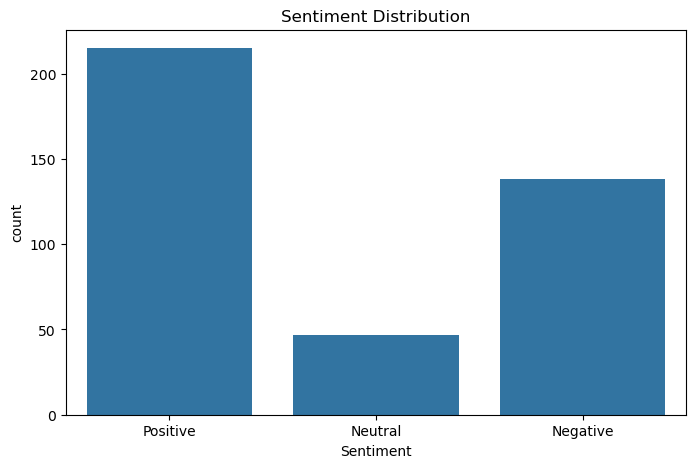

In [2]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Sentiment')
plt.title('Sentiment Distribution')
plt.show()

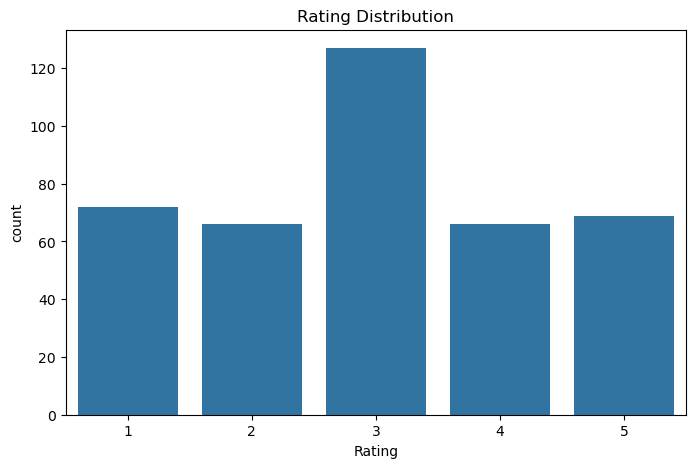

In [3]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Rating')
plt.title('Rating Distribution')
plt.show()

In [4]:
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):

    text = str(text).lower()

    text = re.sub(r'[^a-zA-Z\s]', '', text)

    words = text.split()

    words = [word for word in words if word not in stop_words]

    words = [lemmatizer.lemmatize(word) for word in words]

    return " ".join(words)

df['Clean_Review'] = df['ReviewText'].apply(clean_text)

print(df[['ReviewText','Clean_Review']].head())

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/40eeb96f-4a1c-41ec-96d8-
[nltk_data]     5a12696ba0b5/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /home/40eeb96f-4a1c-41ec-96d8-
[nltk_data]     5a12696ba0b5/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


                                          ReviewText  \
0  I recently switched my car insurance to Blue I...   
1  I recently switched my car insurance to Blue I...   
2  My recent interaction with Blue Insurance was....   
3  I've been with Blue Insurance for several year...   
4  I've been a Blue Insurance customer for over f...   

                                        Clean_Review  
0  recently switched car insurance blue insurance...  
1  recently switched car insurance blue insurance...  
2  recent interaction blue insurance efficient il...  
3  ive blue insurance several year ive always gen...  
4  ive blue insurance customer five year generall...  


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words='english',
    ngram_range=(1,2)
)

X = tfidf.fit_transform(df['Clean_Review'])

print(X.shape)

(400, 5000)


In [7]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    stop_words='english',
    max_features=1000
)

X_topics = vectorizer.fit_transform(df['Clean_Review'])

lda = LatentDirichletAllocation(
    n_components=5,
    random_state=42
)

lda.fit(X_topics)

,n_components,5
,doc_topic_prior,None
,topic_word_prior,None
,learning_method,'batch'
,learning_decay,0.7
,learning_offset,10.0
,max_iter,10
,batch_size,128
,evaluate_every,-1
,total_samples,1000000.0
,perp_tol,0.1


In [8]:
words = vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(lda.components_):

    print(f"\nTopic {topic_idx+1}")

    print([words[i] for i in topic.argsort()[-10:]])


Topic 1
['damage', 'representative', 'ive', 'incredibly', 'process', 'time', 'experience', 'blue', 'claim', 'insurance']

Topic 2
['information', 'payment', 'app', 'year', 'policy', 'customer', 'website', 'ive', 'blue', 'insurance']

Topic 3
['incredibly', 'service', 'sarah', 'felt', 'customer', 'question', 'policy', 'coverage', 'blue', 'insurance']

Topic 4
['felt', 'ive', 'service', 'explanation', 'im', 'experience', 'blue', 'customer', 'policy', 'insurance']

Topic 5
['straightforward', 'recently', 'easy', 'efficient', 'policy', 'online', 'process', 'experience', 'blue', 'insurance']


In [12]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000
)

model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [19]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y = encoder.fit_transform(df['Sentiment'])

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [21]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000
)

model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [22]:
predictions = model.predict(X_test)

In [23]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

accuracy = accuracy_score(y_test, predictions)

print("Accuracy:", accuracy)

print(classification_report(y_test, predictions))

print(confusion_matrix(y_test, predictions))

Accuracy: 0.9875
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        28
           1       1.00      0.86      0.92         7
           2       0.98      1.00      0.99        45

    accuracy                           0.99        80
   macro avg       0.99      0.95      0.97        80
weighted avg       0.99      0.99      0.99        80

[[28  0  0]
 [ 0  6  1]
 [ 0  0 45]]


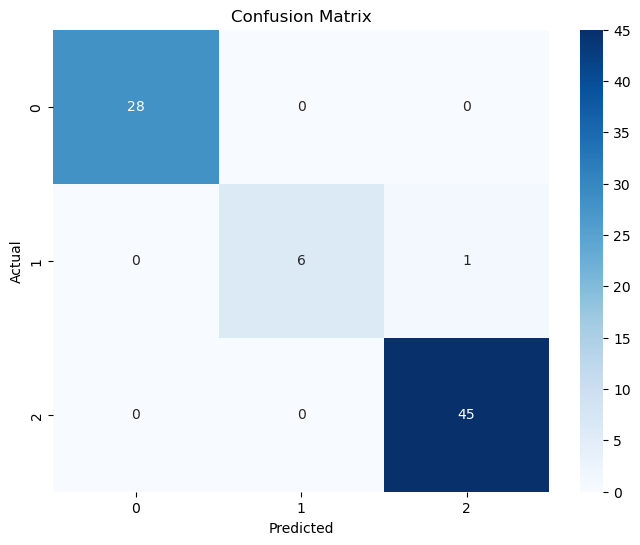

In [24]:
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()